In [1]:
#General tools
import numpy as np
import pandas as pd
import seaborn as sns
import os
import pymol2

#Coded tools, you need to connect it manually sometimes
from generate_graph_new import protein_pocket, make_protein_ligand_complex

#Heatmap tools
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap


In [2]:
#Pocket docking

#Fixed data
dock_pdbqt_dir = '/data/projects/Chemdocking/dock_score/destabilizer_with_poses/'
protein_pdb_dir = "/data/projects/Chemdocking/VirtualDockingLab/data/screen_8000/protein/target.pdb"
complex_pdb_dir = "tmp/complex.pdb"
complex_csv_dir = "complex.csv"
pocket_res = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_poses/stabilizers/'


#poweredge/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_poses/stabilizers/0/1


In [3]:
#Ligand preparation for heatmap
# Filtering through poses

PAH_ligands= {}


#Define iteration through folders
for folder in os.listdir(pocket_res):
    sub_folder= os.path.join(pocket_res, folder)  
    
    #Define iteration through files
    for file in os.listdir(sub_folder):               
        file_path = os.path.join(sub_folder, file)
            
        if file.split('.') [1] != 'csv':
            continue
        if file.split('_') [6] == '2':

            print(file)    #Checkpoint: what files am i opening?
                
            
            #Read your filtered files    
            ligands = pd.read_csv(file_path)
            
            #Create a binary data set to represent the data in a heat map
            ligands_processed = [1 if i in list(ligands['index']) else 0 for i in range(453)]
            
            #Add the data for your dictionary
           
            PAH_ligands[file.split('_')[4]] = ligands_processed
            
            #PAH_ligands.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/stabilizers/stabilizers_pose_1')
            
            #print (PAH_ligands)


dock_smina_PAH_6N1K_40_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_15_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_7_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_9_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_59_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_14_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_3_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_11_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_12_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_39_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_10_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_8_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_35_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_61_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_58_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_56_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_6_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_5_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_55_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_34_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_62_pose_2_stabilizer.csv
dock_smina_PAH_6N1K_37_pose_2_stabilizer.csv
dock_smina_PAH_6

In [4]:
#Dictionary sorting
PAH_ligands_sorted = dict(sorted(PAH_ligands.items(), key=lambda item: int(item[0])))

df_PAH_ligands = pd.DataFrame(PAH_ligands_sorted).T

df_PAH_ligands.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/stabilizers/destabilizers')

#PAH_ligands.items() it will call the dictionary items ( ,  )
#Transform your data into int to sorted, key=lambda sorted by number, not alphabetically

#print (PAH_ligands_sorted)



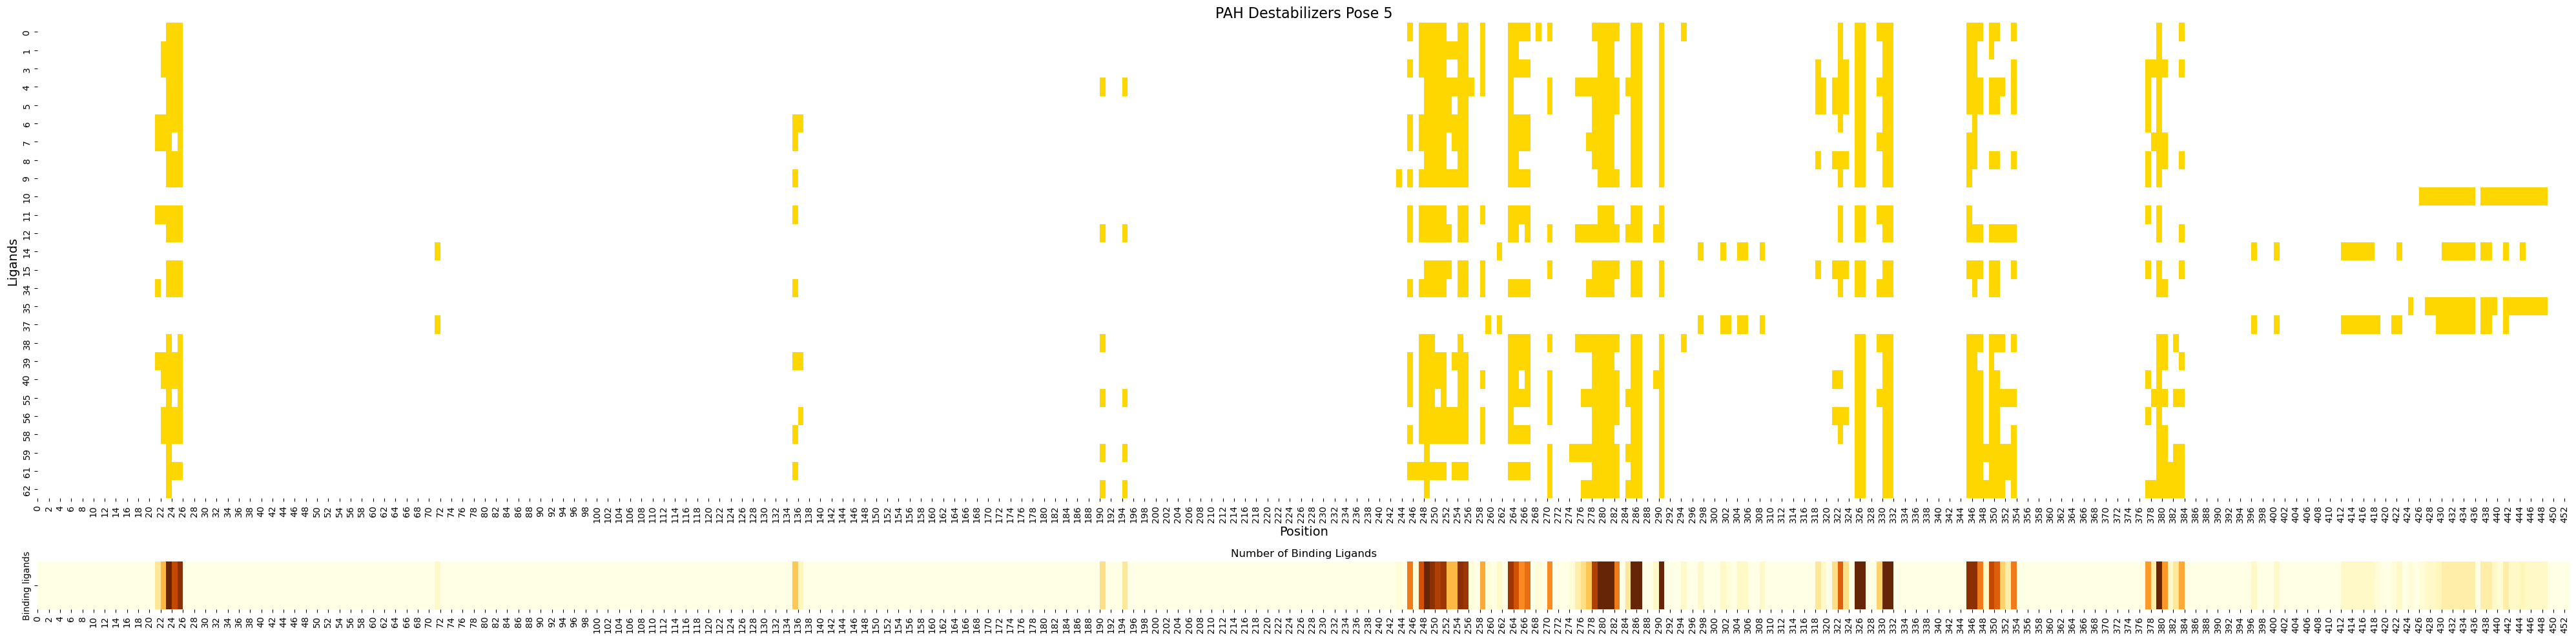

In [14]:

# Create the heatmap layout
fig, ax = plt.subplots(2, 1, figsize=(40, 10), 
                      gridspec_kw={'height_ratios': [1, 0.1]})

# Define x-tick positions (every 2 from 0 to 452)
xticks = np.arange(0, 453, 2)


dark_yellow_cmap = LinearSegmentedColormap.from_list(
    "dark_yellow", ["#FFD700", "#b8860b", "#654321"]
)



# Plot main heatmap (binary matrix)
sns.heatmap(df_PAH_ligands, cmap=["white", "gold"], cbar=False, ax=ax[0], 
            linewidths=0.001, linecolor='gray')

# Title and labels
ax[0].set_title('PAH Destabilizers Pose 5', fontsize=16)
ax[0].set_xlabel('Position', fontsize=14)
ax[0].set_ylabel('Ligands', fontsize=14)
ax[0].tick_params(axis='x', rotation=90)
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)

# Compute sum of 1s per column
heatmap_sum = (df_PAH_ligands == 1).sum(axis=0)
df_heatmap_sum = pd.DataFrame([heatmap_sum], index=["Binding ligands"])

#pink_cmap = LinearSegmentedColormap.from_list("white", ["lightpink","deeppink", "pink"])

# Plot summary heatmap (only one row)
sns.heatmap(df_heatmap_sum, ax=ax[1], cmap="YlOrBr", cbar=False, 
            annot= False, fmt="")
ax[1].set_title("Number of Binding Ligands", fontsize=12)
ax[1].set_xlabel('')
ax[1].set_ylabel('')
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)

# Show the figure
plt.tight_layout()
plt.savefig('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/stabilizers/stabilizers_pose_2_')
plt.show()
